Эеконометрическое моделирование КЕЙС2
-------------------------------------------------
2й кейс - гетероскедастичность h-price тесты (+ анализ визуальной диагностики - гетероскедастичности)
-------------------------------------------------
МЕТОДЫ (перечислены ниже)
1. МНК-регресия, также МНК-регрессия метод Н-с3 или HCCM корректировкой на расчёт стандартных ошибок модели для малых выборок
2. ВМНК (VLS) с изменёнными стандартными ошибками автоматически и руками (Python и excel)
3. ДВМНК (вес задаётся нормативно)
Попробовать на графике приложить модели с корректировкой, после каждой корректировки - диагностика,
(Можно добавить Бокса-Кокса)
сохраняем ряд остатков -> после поправок делать тест на гетероскедастичность
-------------------------------------------------
В основании решить интерпретацию лушего метода, описать итоги

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols

## 1. МНК-регрессия метод НC-3 поправкой

In [58]:
df = pd.read_csv('urozhaynost_usl_own_variance.csv')

In [216]:
X = df.drop('Y', axis=1)
Y = df['Y']

In [219]:
#Через statmodels
model = sm.OLS(Y, sm.add_constant(X)).fit()
model_hc3 = model.get_robustcov_results(cov_type='HC3')

In [235]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.490
Model:                            OLS   Adj. R-squared:                  0.294
Method:                 Least Squares   F-statistic:                     2.499
Date:                Sun, 08 Nov 2026   Prob (F-statistic):             0.0852
Time:                        23:31:29   Log-Likelihood:                -33.461
No. Observations:                  19   AIC:                             78.92
Df Residuals:                      13   BIC:                             84.59
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.0717      6.063      0.837      0.418      -8.026      18.170
X1            -0.1354      1.053     -0.129      0.900      -2.411       2.140
X2             9.0475     24.322      0.372      0.716     -43.498      61.593
X3             0.2732      0.959      0.285      0.780      -1.799       2.345
X4             3.9842      1.670      2.386      0.033       0.377       7.591
X5            -1.2958      3.349     -0.387      0.705      -8.531       5.940
==============================================================================
Omnibus:                        6.728   Durbin-Watson:                   2.583
Prob(Omnibus):                  0.035   Jarque-Bera (JB):                4.373
Skew:                           1.128   Prob(JB):                        0.112
Kurtosis:                       3.660   Cond. No.                         292.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [236]:
model_hc3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.490
Model:                            OLS   Adj. R-squared:                  0.294
Method:                 Least Squares   F-statistic:                     2.314
Date:                Sun, 08 Nov 2026   Prob (F-statistic):              0.104
Time:                        23:33:28   Log-Likelihood:                -33.461
No. Observations:                  19   AIC:                             78.92
Df Residuals:                      13   BIC:                             84.59
Df Model:                           5                                         
Covariance Type:                  HC3                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.0717      5.215      0.972      0.349      -6.195      16.339
X1            -0.1354      1.508     -0.090      0.930      -3.393       3.122
X2             9.0475     21.544      0.420      0.681     -37.496      55.591
X3             0.2732      1.273      0.215      0.833      -2.478       3.024
X4             3.9842      2.224      1.791      0.097      -0.821       8.789
X5            -1.2958      3.258     -0.398      0.697      -8.335       5.743
==============================================================================
Omnibus:                        6.728   Durbin-Watson:                   2.583
Prob(Omnibus):                  0.035   Jarque-Bera (JB):                4.373
Skew:                           1.128   Prob(JB):                        0.112
Kurtosis:                       3.660   Cond. No.                         292.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [233]:
bp_test = sms.het_breuschpagan(model.resid, model.model.exog)

# Создаем красивую таблицу
bp_table = pd.DataFrame({
    'Показатель': ['Статистика LM', 'p-value', 'F-статистика', 'F p-value'],
    'Значение': [round(bp_test[0], 4), round(bp_test[1], 4), round(bp_test[2], 4), round(bp_test[3], 4)]
})

print("Результаты теста Бройша-Пагана:")
display(bp_table)

Результаты теста Бройша-Пагана:


,Показатель,Значение
0,Статистика LM,3.4222
1,p-value,0.6352
2,F-статистика,0.5712
3,F p-value,0.7211


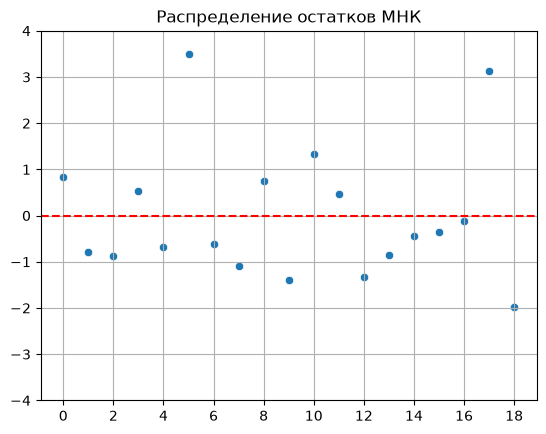

In [225]:
sns.scatterplot(model.resid)
plt.ylim((-4, 4))
plt.axhline(0, linestyle='--', color='red')
plt.grid(True)
plt.title('Распределение остатков МНК')
plt.xticks(range(0, len(model.resid), 2))
plt.savefig('residuals_МНК.png', dpi=300, bbox_inches='tight');

## 2. ВМНК (WLS) с изменёнными стандартными ошибками

In [185]:
model = ols(f"Y ~ {'+'.join(df.drop('Y', axis=1).columns)}", df).fit()

In [193]:
# --- ПОДГОТОВКА ДАННЫХ ---
X_raw = df.drop('Y', axis=1)
y_raw = df['Y']
X_mat = np.asarray(sm.add_constant(X_raw))  # Матрица (19, 6)
y_mat = np.asarray(y_raw).reshape(-1, 1)    # Вектор-столбец (19, 1)

In [194]:
# --- ШАГ 1: Считаем веса ---
# (Модель для логарифма остатков)
log_e = np.log((model.resid) ** 2) # или взять model.resid
Extended_model = sm.OLS(log_e, X_mat).fit()
variances = np.exp(Extended_model.predict(X_mat)) # (19,)
w = 1 / variances # (19,) - это наши веса!

In [196]:
# --- ШАГ 2: Ручной расчет B_wls (если не сделали) ---
W = np.diag(w)
B_wls = np.linalg.inv(X_mat.T @ W @ X_mat) @ (X_mat.T @ W @ y_mat)

In [197]:
# 1. Остатки от ВМНК (превращаем в одномерный массив)
y_pred_wls = X_mat @ B_wls
e_wls = (y_mat - y_pred_wls).ravel() # (19,)

In [198]:
# 2. Корень из весов
sqrt_w = np.sqrt(w).ravel() # (19,)

In [199]:
# 3. Взвешенная матрица X* и взвешенные остатки e*
# В NumPy лучше умножать каждую СТРОКУ X_mat на sqrt_w. 
# Для этого можно умножить X_mat на sqrt_w[:, None] (добавит измерение столбца)
X_star = X_mat * sqrt_w[:, None] 
e_star = e_wls * sqrt_w

In [200]:
# 4. Рычаги h_ii для взвешенной модели
XtX_star_inv = np.linalg.inv(X_star.T @ X_star)
H_star = X_star @ XtX_star_inv @ X_star.T
h_star = H_star.diagonal()

In [201]:
# 5. Веса для HC3
omega = (e_star ** 2) / ((1 - h_star) ** 2)
Omega = np.diag(omega)

In [202]:
# 6. Собираем "сэндвич" для ВМНК
cov_wls_hc3 = XtX_star_inv @ (X_star.T @ Omega @ X_star) @ XtX_star_inv

In [203]:
# 7. Извлекаем стандартные ошибки
se_wls_hc3 = np.sqrt(np.diag(cov_wls_hc3))
print("Стандартные ошибки ВМНК (HC3):")
print(se_wls_hc3)

Стандартные ошибки ВМНК (HC3):
[ 3.45645284  1.20157439 13.62353713  0.98010781  1.87550245  2.41889746]


---------------------------------------------------------------------------

In [242]:
model_wls = sm.WLS(Y, sm.add_constant(X), weights=w).fit()
model_wls.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            WLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.796
Model:                            WLS   Adj. R-squared:                  0.717
Method:                 Least Squares   F-statistic:                     10.12
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           0.000400
Time:                        23:50:16   Log-Likelihood:                -28.840
No. Observations:                  19   AIC:                             69.68
Df Residuals:                      13   BIC:                             75.35
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.8470      3.951      1.227      0.242      -3.688      13.382
X1            -0.4574      1.056     -0.433      0.672      -2.738       1.823
X2             8.8068     16.336      0.539      0.599     -26.485      44.099
X3             0.6093      0.889      0.685      0.505      -1.311       2.530
X4             5.1771      1.767      2.930      0.012       1.360       8.994
X5            -2.6311      2.732     -0.963      0.353      -8.533       3.271
==============================================================================
Omnibus:                        4.885   Durbin-Watson:                   2.574
Prob(Omnibus):                  0.087   Jarque-Bera (JB):                2.920
Skew:                           0.932   Prob(JB):                        0.232
Kurtosis:                       3.459   Cond. No.                         520.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [243]:
model_wls_hc3 = model_wls.get_robustcov_results(cov_type='HC3')
model_wls_hc3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            WLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.796
Model:                            WLS   Adj. R-squared:                  0.717
Method:                 Least Squares   F-statistic:                     7.758
Date:                Sun, 08 Nov 2026   Prob (F-statistic):            0.00141
Time:                        23:50:29   Log-Likelihood:                -28.840
No. Observations:                  19   AIC:                             69.68
Df Residuals:                      13   BIC:                             75.35
Df Model:                           5                                         
Covariance Type:                  HC3                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.8470      3.456      1.402      0.184      -2.620      12.314
X1            -0.4574      1.202     -0.381      0.710      -3.053       2.138
X2             8.8068     13.624      0.646      0.529     -20.625      38.239
X3             0.6093      0.980      0.622      0.545      -1.508       2.727
X4             5.1771      1.876      2.760      0.016       1.125       9.229
X5            -2.6311      2.419     -1.088      0.296      -7.857       2.595
==============================================================================
Omnibus:                        4.885   Durbin-Watson:                   2.574
Prob(Omnibus):                  0.087   Jarque-Bera (JB):                2.920
Skew:                           0.932   Prob(JB):                        0.232
Kurtosis:                       3.459   Cond. No.                         520.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [238]:
bp_test_wls = sms.het_breuschpagan(model_wls.resid, model_wls.model.exog)

# Создаем красивую таблицу
bp_wls_table = pd.DataFrame({
    'Показатель': ['Статистика LM', 'p-value', 'F-статистика', 'F p-value'],
    'Значение': [round(bp_test_wls[0], 4), round(bp_test_wls[1], 4), round(bp_test_wls[2], 4), round(bp_test_wls[3], 4)]
})

print("Результаты теста Бройша-Пагана:")
display(bp_wls_table)

Результаты теста Бройша-Пагана:


,Показатель,Значение
0,Статистика LM,4.6911
1,p-value,0.4547
2,F-статистика,0.8524
3,F p-value,0.5373


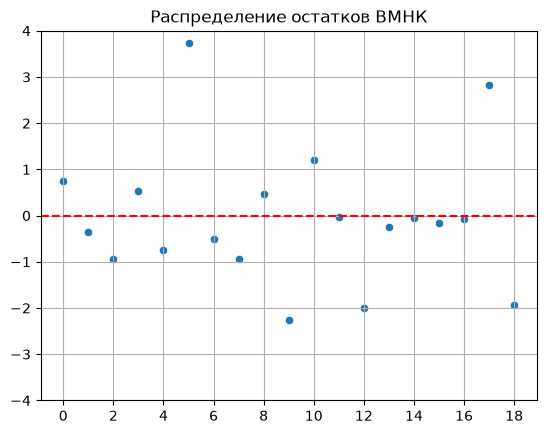

In [244]:
sns.scatterplot(model_wls_hc3.resid)
plt.ylim((-4, 4))
plt.axhline(0, linestyle='--', color='red')
plt.grid(True)
plt.title('Распределение остатков ВМНК')
plt.xticks(range(0, len(model_wls.resid), 2));
plt.savefig('residuals_ВМНК.png', dpi=300, bbox_inches='tight');

## 3. ДВМНК (вес задаётся нормативно)